In [22]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make `import aml` work even if the package hasn't been installed with `pip install -e .`
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.cleaning import add_flags, add_node_ids, add_usd_amounts, estimate_fx_rates, trim_after
from aml.config import Config
from aml.io import load_accounts, load_patterns, load_transactions
from aml.patterns import match_patterns, pattern_coverage
from aml.pipeline import clean
from aml.quality import daily_profile, laundering_rate_by, quality_report
from aml.splitting import split_summary

config = Config()
paths = config.paths
FIG = paths.figures_dir
FIG.mkdir(parents=True, exist_ok=True)

from aml.plotting import LAUNDERING, MUTED, NORMAL, set_style, save
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 30)

def savefig(name):
    save(plt.gcf(), FIG, name)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Loading and validating the new file 

In [23]:
raw = load_transactions(paths.transactions_csv)
print(f"{len(raw):,} rows | {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")
raw.head()

17:39:47 | INFO | aml.io | Reading HI-Small_Trans.csv
17:39:55 | INFO | aml.io | Loaded 5,078,345 transactions


5,078,345 rows | 0.50 GB in memory


,tx_id,timestamp,from_bank,from_account,to_bank,to_account,amount_received,recv_currency,amount_paid,pay_currency,payment_format,is_laundering
0,0,2022-09-01 00:20:00,010,8000EBD30,010,8000EBD30,"3,697.3400",US Dollar,"3,697.3400",US Dollar,Reinvestment,0
1,1,2022-09-01 00:20:00,03208,8000F4580,001,8000F5340,0.0100,US Dollar,0.0100,US Dollar,Cheque,0
2,2,2022-09-01 00:00:00,03209,8000F4670,03209,8000F4670,"14,675.5700",US Dollar,"14,675.5700",US Dollar,Reinvestment,0
3,3,2022-09-01 00:02:00,012,8000F5030,012,8000F5030,"2,806.9700",US Dollar,"2,806.9700",US Dollar,Reinvestment,0
4,4,2022-09-01 00:06:00,010,8000F5200,010,8000F5200,"36,682.9700",US Dollar,"36,682.9700",US Dollar,Reinvestment,0


In [24]:
raw.dtypes

tx_id                       int64
timestamp          datetime64[us]
from_bank                     str
from_account                  str
to_bank                       str
to_account                    str
amount_received           float64
recv_currency            category
amount_paid               float64
pay_currency             category
payment_format           category
is_laundering                int8
dtype: object

## 3. Data quality

In [25]:
report = quality_report(raw)
report

{'rows': 5078345,
 'nulls_per_column': {},
 'exact_duplicate_rows': 9,
 'nonpositive_amount_paid': 0,
 'nonpositive_amount_received': 0,
 'time_min': '2022-09-01 00:00:00',
 'time_max': '2022-09-18 16:18:00',
 'laundering_rows': 5177,
 'laundering_rate': 0.0010194266045335635}

In [ ]:

raw["from_bank"].str.len().value_counts().sort_index().rename("from_bank code length")

from_bank
3    1070869
4     400848
5     466050
6    1662832
7    1477746
Name: from_bank code length, dtype: int64

In [ ]:

pairs = pd.concat([
    raw[["from_bank", "from_account"]].set_axis(["bank", "account"], axis=1),
    raw[["to_bank", "to_account"]].set_axis(["bank", "account"], axis=1),
]).drop_duplicates()
print(f"unique account numbers:      {pairs['account'].nunique():,}")
print(f"unique (bank, account) pairs: {len(pairs):,}")
del pairs

unique account numbers:      515,080
unique (bank, account) pairs: 515,088


In [28]:
daily = daily_profile(raw, amount_col="amount_paid")
daily

,tx,laundering,usd_volume,laundering_rate
date,,,,
2022-09-01,1114921,322,"6,441,442,674,817.2842",0.0003
2022-09-02,754449,408,"5,059,368,272,413.6299",0.0005
2022-09-03,207382,391,"562,282,508,314.0903",0.0019
2022-09-04,207430,407,"425,080,583,859.4792",0.0020
2022-09-05,482650,471,"1,214,661,318,712.1238",0.0010
2022-09-06,482089,531,"2,505,941,411,669.8657",0.0011
2022-09-07,482751,497,"2,263,913,197,532.3076",0.0010
2022-09-08,482773,539,"1,203,569,882,886.2476",0.0011
2022-09-09,654467,514,"2,841,475,561,178.3848",0.0008


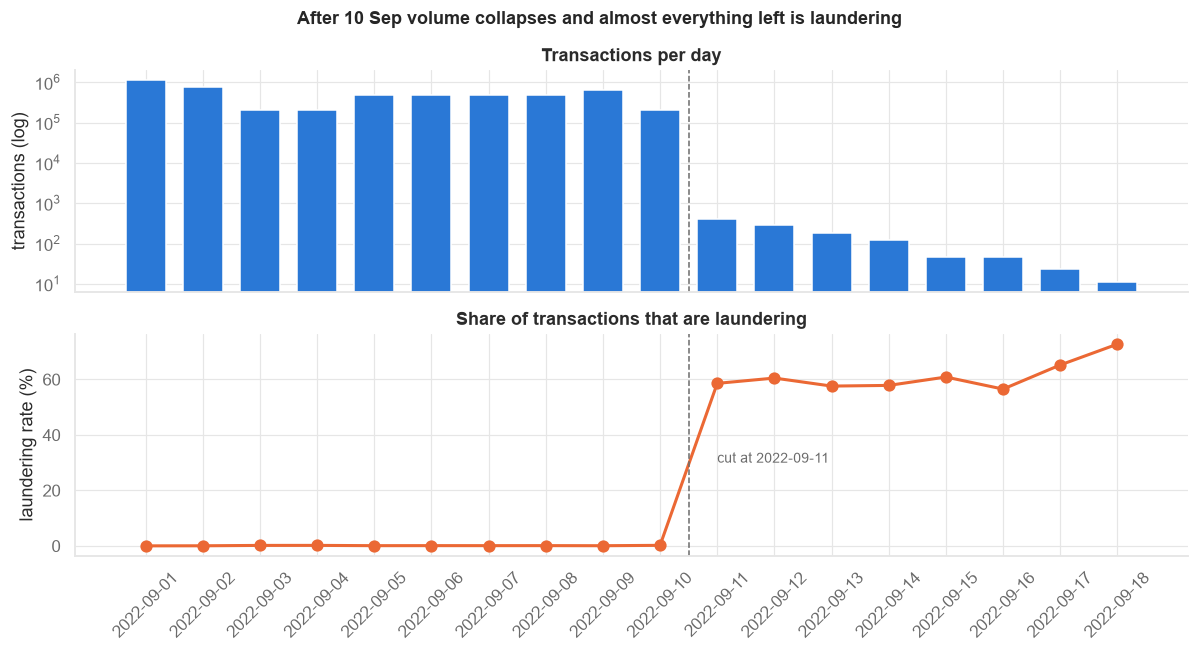

In [29]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, height_ratios=[1, 1])
days = daily.index.astype(str)
ax1.bar(days, daily["tx"], color=NORMAL, width=0.7)
ax1.set_yscale("log")
ax1.set_ylabel("transactions (log)")
ax1.set_title("Transactions per day")
ax2.plot(days, daily["laundering_rate"] * 100, color=LAUNDERING, marker="o", markersize=7)
ax2.set_ylabel("laundering rate (%)")
ax2.set_title("Share of transactions that are laundering")
ax2.tick_params(axis="x", rotation=45)
for ax in (ax1, ax2):
    ax.axvline(9.5, color=MUTED, linestyle="--", linewidth=1)
ax2.annotate("cut at 2022-09-11", xy=(9.5, 30), xytext=(10.0, 30), color=MUTED, fontsize=9)
fig.suptitle("After 10 Sep volume collapses and almost everything left is laundering", fontweight="bold")
plt.tight_layout()
savefig("01_daily_profile")
plt.show()

In [30]:
cut = config.cleaning.max_date
tail = raw[raw["timestamp"] >= cut]
print(f"Rows on/after {cut}: {len(tail):,} ({tail['is_laundering'].mean():.1%} laundering) -> removed in cleaning")

Rows on/after 2022-09-11: 1,108 (59.1% laundering) -> removed in cleaning


## Payment formats, currencies, self-loops

In [31]:
df = trim_after(raw, config.cleaning.max_date)
df, nodes = add_node_ids(df)
fx_rates, fx_diag = estimate_fx_rates(df)
df = add_usd_amounts(df, fx_rates)
df, format_codes = add_flags(df)
by_format = laundering_rate_by(df, "payment_format")
by_format

17:40:05 | INFO | aml.cleaning | Trimming 1,108 transactions on/after 2022-09-11
17:40:24 | INFO | aml.cleaning | Built 515,078 nodes from bank+account pairs


,tx,laundering,laundering_rate,share_of_laundering
payment_format,,,,
ACH,599689,3828,0.0064,0.8465
Bitcoin,146091,56,0.0004,0.0124
Cash,490891,108,0.0002,0.0239
Cheque,1864331,324,0.0002,0.0716
Credit Card,1323324,206,0.0002,0.0456
Reinvestment,481056,0,0.0000,0.0000
Wire,171855,0,0.0000,0.0000


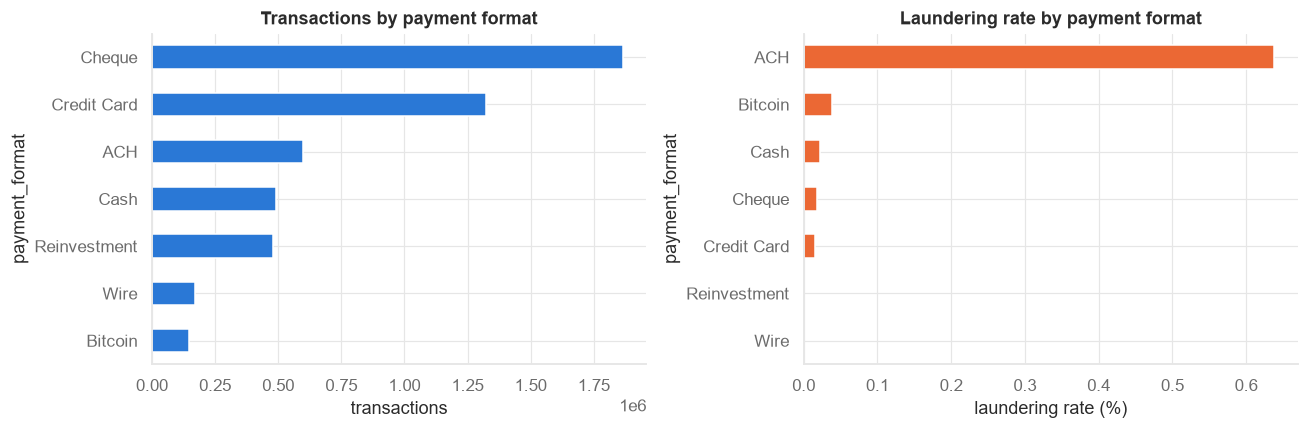

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_format["tx"].sort_values().plot.barh(ax=axes[0], color=NORMAL)
axes[0].set_title("Transactions by payment format")
axes[0].set_xlabel("transactions")
(by_format["laundering_rate"] * 100).sort_values().plot.barh(ax=axes[1], color=LAUNDERING)
axes[1].set_title("Laundering rate by payment format")
axes[1].set_xlabel("laundering rate (%)")
plt.tight_layout()
savefig("02_payment_formats")
plt.show()

In [33]:
pd.concat({
    "cross_currency": laundering_rate_by(df, "is_cross_currency"),
    "self_loop": laundering_rate_by(df, "is_self_loop"),
    "cross_bank": laundering_rate_by(df, "is_cross_bank"),
})

tx  laundering  laundering_rate  share_of_laundering
cross_currency 0  5005458        4522           0.0009               1.0000
               1    71779           0           0.0000               0.0000
self_loop      0  4486418        4514           0.0010               0.9982
               1   590819           8           0.0000               0.0018
cross_bank     1  4386319        4439           0.0010               0.9816
               0   690918          83           0.0001               0.0184

In [34]:
fx_diag.sort_values('coef_of_variation', ascending=False)

,rate,n_rows,coef_of_variation
currency,,,
Bitcoin,"11,875.0000",1509,0.1589
Yen,0.0095,3052,0.0205
Ruble,0.0129,2089,0.0177
Shekel,0.2961,2247,0.0148
Yuan,0.1493,9200,0.0113
Canadian Dollar,0.7580,2081,0.0100
Australian Dollar,0.7078,1530,0.0075
Mexican Peso,0.0473,1185,0.0072
Brazil Real,0.1771,832,0.0067


## Amounts

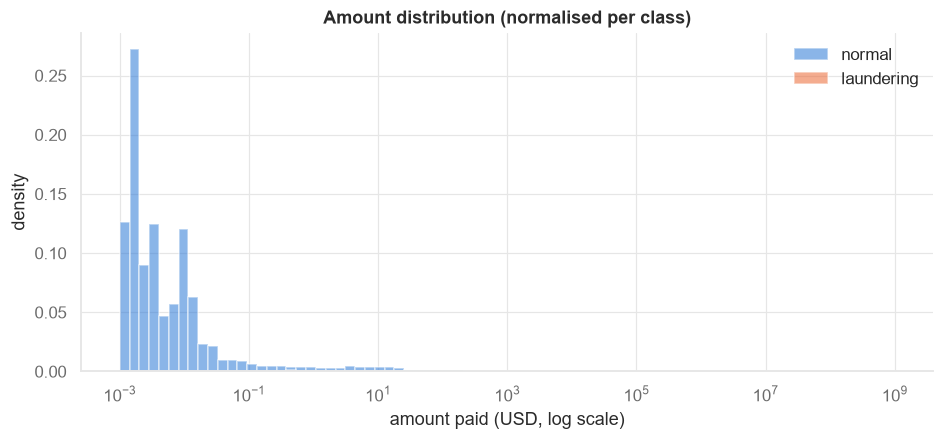

In [35]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(-3, 9, 80)
for label, color in [(0, NORMAL), (1, LAUNDERING)]:
    s = df.loc[(df["is_laundering"] == label) & (df["amount_paid_usd"] > 0), "amount_paid_usd"]
    ax.hist(s, bins=bins, density=True, alpha=0.55, color=color, label="laundering" if label else "normal")
ax.set_xscale("log")
ax.set_xlabel("amount paid (USD, log scale)")
ax.set_ylabel("density")
ax.set_title("Amount distribution (normalised per class)")
ax.legend()
savefig("03_amounts")
plt.show()

In [36]:
df.groupby("is_laundering")["amount_paid_usd"].describe(percentiles=[0.1, 0.5, 0.9, 0.99])

,count,mean,std,min,10%,50%,90%,99%,max
is_laundering,,,,,,,,,
0,"5,072,715.0000","346,032.0884","23,234,406.0644",0.0001,29.9977,890.8718,"35,451.3944","3,099,588.9900","26,558,612,904.5284"
1,"4,522.0000","5,868,499.6736","247,513,266.6704",0.3867,473.6310,"5,074.0150","18,383.7390","19,360,300.8829","16,297,045,508.7409"


## Accounts as graph

In [37]:
edges = df[df["is_self_loop"] == 0]
out_deg = edges.groupby("from_idx")["to_idx"].nunique()
in_deg = edges.groupby("to_idx")["from_idx"].nunique()

launder_nodes = pd.Index(pd.unique(np.concatenate([
    df.loc[df["is_laundering"] == 1, "from_idx"], df.loc[df["is_laundering"] == 1, "to_idx"]])))
node_stats = pd.DataFrame({"out_counterparties": out_deg, "in_counterparties": in_deg}).fillna(0)
node_stats["touches_laundering"] = node_stats.index.isin(launder_nodes)

print(f"nodes with any non-self transaction: {len(node_stats):,}")
print(f"nodes involved in >=1 laundering tx: {node_stats['touches_laundering'].sum():,}")
node_stats.groupby("touches_laundering")[["out_counterparties", "in_counterparties"]].describe().T

nodes with any non-self transaction: 422,656
nodes involved in >=1 laundering tx: 5,862


touches_laundering              False       True 
out_counterparties count 416,794.0000  5,862.0000
                   mean        1.4342      8.4519
                   std         1.9851    226.0879
                   min         0.0000      0.0000
                   25%         0.0000      1.0000
                   50%         1.0000      1.0000
                   75%         2.0000      2.0000
                   max        35.0000 14,230.0000
in_counterparties  count 416,794.0000  5,862.0000
                   mean        1.5050      3.4207
                   std         2.4484     10.1101
                   min         0.0000      0.0000
                   25%         0.0000      1.0000
                   50%         1.0000      2.0000
                   75%         2.0000      3.0000
                   max        93.0000    545.0000

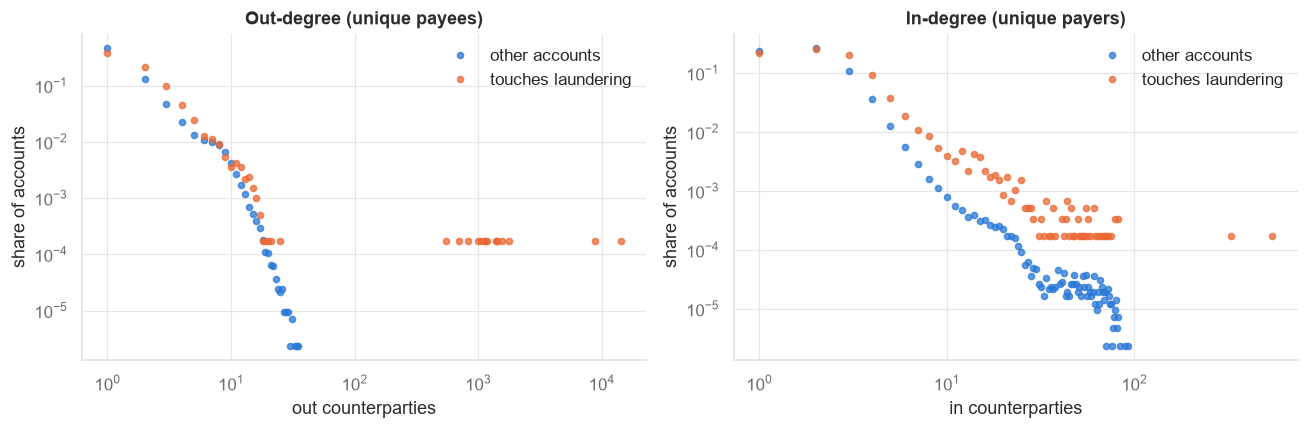

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["out_counterparties", "in_counterparties"]):
    for flag, color in [(False, NORMAL), (True, LAUNDERING)]:
        counts = node_stats.loc[node_stats["touches_laundering"] == flag, col].value_counts(normalize=True).sort_index()
        counts = counts[counts.index > 0]
        ax.loglog(counts.index, counts.values, "o", markersize=4, color=color, alpha=0.75,
                  label="touches laundering" if flag else "other accounts")
    ax.set_xlabel(col.replace("_", " "))
    ax.set_ylabel("share of accounts")
    ax.legend()
axes[0].set_title("Out-degree (unique payees)")
axes[1].set_title("In-degree (unique payers)")
plt.tight_layout()
savefig("04_degree_distribution")
plt.show()

## The Pattern file

In [39]:
patterns = load_patterns(paths.patterns_txt)
patterns.groupby("pattern_type").agg(
    attempts=("attempt_id", "nunique"),
    transactions=("attempt_id", "size"),
).assign(tx_per_attempt=lambda t: t["transactions"] / t["attempts"]).sort_values("attempts", ascending=False)

17:40:44 | WARNING | aml.io | Patterns file: skipped 1 malformed or orphan line(s)
17:40:44 | WARNING | aml.io | Patterns file: 1 attempt(s) have no END line (file may be truncated)
17:40:44 | INFO | aml.io | Parsed 118 attempts, 1005 transactions from HI-Small_Patterns.txt


,attempts,transactions,tx_per_attempt
pattern_type,,,
BIPARTITE,19,104,5.4737
CYCLE,19,81,4.2632
FAN-OUT,18,128,7.1111
GATHER-SCATTER,18,268,14.8889
FAN-IN,12,94,7.8333
SCATTER-GATHER,12,166,13.8333
STACK,12,128,10.6667
RANDOM,8,36,4.5000


In [40]:
matched = match_patterns(df, patterns)
coverage = pattern_coverage(df, matched)
coverage

17:40:53 | INFO | aml.patterns | Matched 1004 of 1005 pattern rows to transactions


{'laundering_tx': 4522,
 'laundering_tx_in_patterns': 1004,
 'laundering_tx_without_pattern': 3518,
 'pattern_tx_not_labelled_laundering': 0}

## Cleaning and splitting

In [41]:
result = clean(raw, config)
clean_df = result.transactions
split_summary(clean_df)

17:40:59 | INFO | aml.cleaning | Trimming 1,108 transactions on/after 2022-09-11
17:41:18 | INFO | aml.cleaning | Built 515,078 nodes from bank+account pairs


,rows,laundering,laundering_rate,start,end
split,,,,,
train,3046186,2296,0.0008,2022-09-01 00:00:00,2022-09-06 13:33:00
val,1015300,1083,0.0011,2022-09-06 13:34:00,2022-09-08 16:08:00
test,1015751,1143,0.0011,2022-09-08 16:09:00,2022-09-10 23:59:00


In [42]:
assert clean_df.groupby("split", observed=True)["timestamp"].agg(["min", "max"]).pipe(
    lambda t: (t["max"].shift() < t["min"]).iloc[1:].all()), "splits overlap in time"
assert clean_df["tx_id"].is_unique
assert clean_df[["from_idx", "to_idx"]].min().min() >= 0
print("Split checks passed")

Split checks passed
